# Mandatory assignment 3

**GitHub repository:** https://github.com/leohohner/TECH2-H26_Assignment3


## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

## Question 1

In [1]:
import pandas as pd 

#Load File with Data Frame
file = "SCF_10pct.csv"
df = pd.read_csv(file)

#Print the column names to check that all are there
print(f" The data columns are: {df.columns}")

#Count number of missing data values:
print(f"Number of non N/A data values are:{df.count()}")




#Count the number of people who are in the data
#Number_of_measurements = len(df)

#Count the Number of people who have values
#equity_number = df["equity"].count()
#stocks_number = df["stocks"].count()

#Find the number of people

#print(equity_number)
#print(stocks_number)
#print(Number_of_measurements)


 The data columns are: Index(['id', 'year', 'age', 'educ', 'stocks', 'equity'], dtype='str')
Number of non N/A data values are:id        5808
year      5808
age       5808
educ      5792
stocks    5790
equity    5792
dtype: int64


## Question 2

In [75]:
variables = ["id", "year", "age", "educ", "stocks", "equity"]

for variable in variables:
    missing = df[variable].isna().sum()
    print(variable, ":", missing, "missing observations")
#Now we have a count of the missing obervations

#Now we need to store previous count before we drop all the NA´s
n_before = len(df)

#Lets drop the NA´s and count the new number of observation
df = df.dropna(subset=variables)

n_after = len(df)
dropped_observations = n_before - n_after

print(f"Total dropped observations: {dropped_observations}")
print(f"Total remaining observations: {n_after}")


id : 0 missing observations
year : 0 missing observations
age : 0 missing observations
educ : 16 missing observations
stocks : 18 missing observations
equity : 16 missing observations
Total dropped observations: 50
Total remaining observations: 5758


## Question 3

In [76]:
n_before_age = len(df)

df = df.query("age >= 25 and age <= 89")

n_after_age = len(df)
dropped_age = n_before_age - n_after_age

print(f"Observations dropped due to age: {dropped_age}")
print(f"Observations remaining: {n_after_age}")

Observations dropped due to age: 326
Observations remaining: 5432


## Question 4

In [10]:
#4. Create two 0/1 indicator columns:
 #  - `direct`: 1 if the household participates directly (`stocks > 0`),
 #    0 otherwise.
 #  - `overall`: 1 if the household participates directly or indirectly
  #   (`equity > 0`), 0 otherwise.

#Translate participation into Boolean expressions
stock_participation = df["stocks"] > 0
overall_participation = df["equity"] > 0

#Tanslate Boolen expressions into binary
stock_participation = stock_participation.astype(int)
overall_participation = overall_participation.astype(int)

# Add the results as new columns in the DataFrame

df["direct"] = stock_participation
df["overall"] = overall_participation

df

,id,year,age,educ,stocks,equity,direct,overall
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
3,3,1989,23,2.0,0.0,0.0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0
...,...,...,...,...,...,...,...,...
5803,5803,2022,21,2.0,0.0,0.0,0,0
5804,5804,2022,33,3.0,0.0,0.0,0,0
5805,5805,2022,81,2.0,100000.0,100000.0,1,1
5806,5806,2022,58,3.0,40000.0,1212000.0,1,1


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [ ]:
#1 Define the function
def participation_rate(indicator):
    """This function calculates the average value of participation rate based on the number of participants"""
    total = 0 
    #Loop through each observation and add them 
    for obs in indicator:
        total += obs 
    total_obs = len(indicator)
    rate = total / total_obs * 100
    return rate

#Apply Function to direct
rate_stock_participation = participation_rate(df["direct"])
print(total_stock_participation)

#Apply Function to overall
rate_overall_participation = participation_rate(df["overall"])
print(total_overall_participation)

16.546143250688704
48.10606060606061


In [25]:
#Now use Pandas in-built finction
rate_stock_participation = df["direct"].mean() * 100
print(total_stock_participation)

rate_overall_participation = df["overall"].mean() * 100
print(rate_overall_participation)

16.546143250688704
48.10606060606061


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

In [105]:
#education_1 = df[df["educ"] == 1]

Direct_Participation_Education = []
Overall_Participation_Education = []

print("Direct Participation based on increasing levels of education in %:")
for level in range(1, 5):
    education_level = df[df["educ"] == level]
    rate_stock_participation_education = participation_rate(education_level["direct"])
    Direct_Participation_Education.append(round(rate_stock_participation_education,1))

print(Direct_Participation_Education)

print()

print("Overall Participation based on increasing levels of education in %:")
for level in range(1, 5):
    education_level = df[df["educ"] == level]
    rate_overall_participation_education = participation_rate(education_level["overall"])
    Overall_Participation_Education.append(round(rate_overall_participation_education,1))

print(Overall_Participation_Education)


Direct Participation based on increasing levels of education in %:
[4.2, 10.9, 13.4, 30.3]

Overall Participation based on increasing levels of education in %:
[16.5, 38.6, 46.7, 72.8]


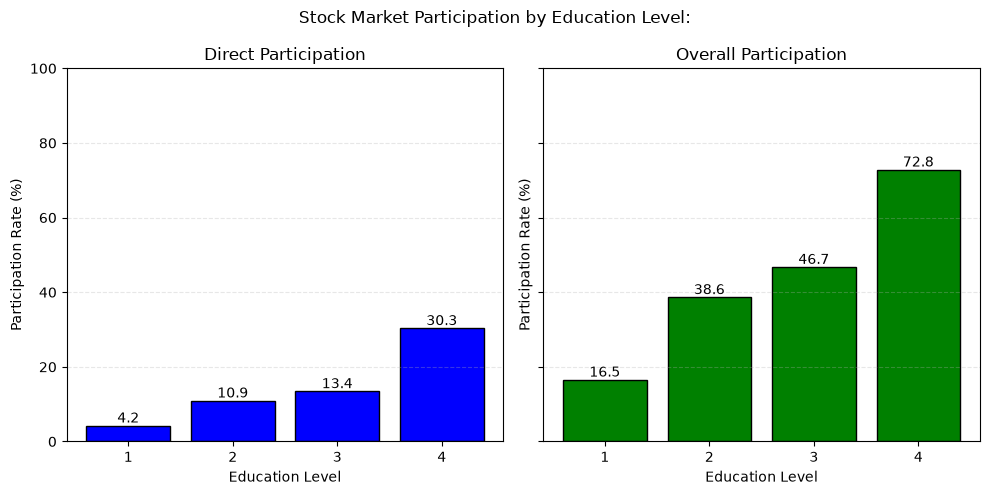

In [150]:
import matplotlib.pyplot as plt


education_levels = [1, 2, 3, 4]

fig, ax = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
fig.suptitle("Stock Market Participation by Education Level:")


#Direct participation
ax[0].bar(education_levels, Direct_Participation_Education, color="blue", edgecolor="black")
ax[0].set_title("Direct Participation")
ax[0].set_xlabel("Education Level")
ax[0].set_ylabel("Participation Rate (%)")
ax[0].set_xticks(education_levels)
ax[0].set_ylim(0,100)
ax[0].grid(axis="y", linestyle="--", alpha=0.3)


#Overall participation
ax[1].bar(education_levels, Overall_Participation_Education, color="green", edgecolor="black")
ax[1].set_title("Overall Participation")
ax[1].set_xlabel("Education Level")
ax[1].set_ylabel("Participation Rate (%)")
ax[1].set_xticks(education_levels)
ax[1].set_ylim(0,100)
ax[1].grid(axis="y", linestyle="--", alpha=0.3)

#Now add percentage labels
# Percentage labels
ax[0].bar_label(bars1)
ax[1].bar_label(bars2)

plt.tight_layout()
plt.show()

It is observed that in both cases, the participation rate increases proportionally to the increase in Education Levels. The Overall participation follows roughly the same rate of increase as the Direct Participation. There is a significant increase from level 3 to 4 compared to increases in the other levels.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

In [ ]:
direct_participation_time = []
overall_participation_time = []

print("Direct Participation based on changes in time:")
for time in range(1989, 2023, 3):
    i = df[df["year"] == time]
    rate_stock_participation_time = participation_rate(i["direct"])
    direct_participation_time.append(round(rate_stock_participation_time,1))

print(direct_participation_time)


print("Overall Participation based on changes in time:")
for time in range(1989, 2023, 3):
    i = df[df["year"] == time]
    rate_overall_participation_time = participation_rate(i["overall"])
    overall_participation_time.append(round(rate_overall_participation_time,1))

print(overall_participation_time)


Direct Participation based on changes in time:
[15.3, 17.8, 15.1, 19.6, 20.9, 18.4, 15.9, 16.5, 14.7, 12.6, 12.8, 19.0]
Overall Participation based on changes in time:
[30.8, 39.3, 44.2, 49.6, 56.2, 52.9, 53.3, 48.8, 49.0, 51.0, 48.3, 53.9]


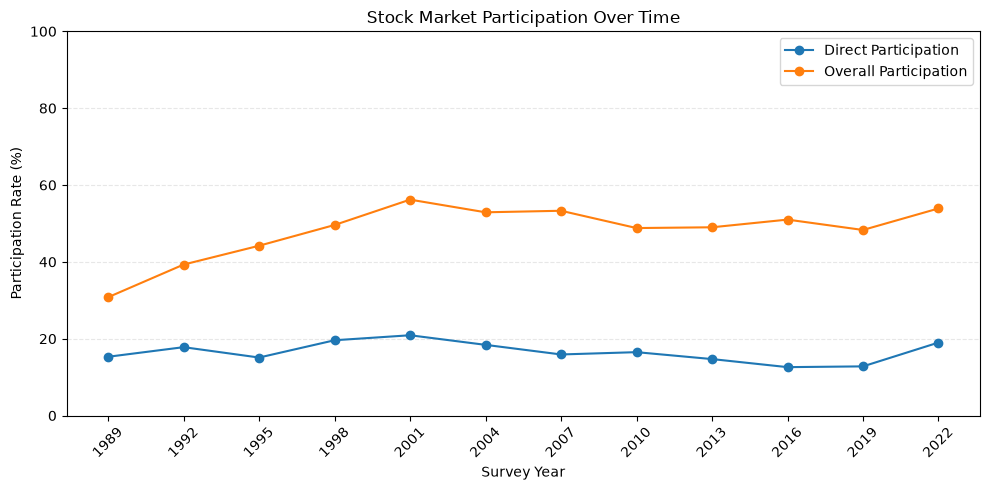

In [158]:
import matplotlib.pyplot as Richard

time_frame = []
for i in range(1989, 2023, 3):
    time_frame.append(i)

Richard.figure(figsize=(10, 5))

# First curve, Direct participation
Richard.plot(time_frame, direct_participation_time, marker="o", label="Direct Participation")

# Second curve, Overall participation
Richard.plot(time_frame, overall_participation_time, marker="o", label="Overall Participation")

Richard.title("Stock Market Participation Over Time")
Richard.xlabel("Survey Year")
Richard.ylabel("Participation Rate (%)")

Richard.legend()
Richard.grid(axis="y", linestyle="--", alpha=0.3)

Richard.xticks(time_frame, rotation=45)
Richard.ylim(0, 100)

Richard.tight_layout()
Richard.show()


In [ ]:
direct_change = direct_participation_time[-1] - direct_participation_time[0]
overall_change = overall_participation_time[-1] - overall_participation_time[0]

print(f" The direct change in Stock participation was: {direct_change:.1f} PP \n While the overall change was: {overall_change:.1f} PP")

 The direct change in Stock participation was: 3.7 PP 
 While the overall change was 23.1 PP


# Question 4
It is apparent that Overall participation has had a much larger increase in participation than compared to Direct Participation, 23PP vs 3.7PP. Over the selected period, participation rates rose steadily for Overall participation from 1989 up to 2001 when it hit a peak, and afterwards roughly platoed. Direct participation fluctated a bit over the years but mostly remained constant.

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

I used ai in specific situation where i did not remember the name for a function and could not find it in the lectures. This was mainly done through selected prompts into googles built-in ai like "what is the function for gridlines in matplotlib" or "how do you convert boolean strings into binary". This is mainly done because i find the provided cheatsheet unbelively time consuming to read and find specific code from previous lecture slides also takes a while.